# A trained plate between two polarizers

Checks [`docs/networks/polarizer-classifier.md`](../../docs/networks/polarizer-classifier.md): the building blocks of
polarized light, the grating table (P1), and the verdicts on P2 to P4 for the trained devices. The model is the one in
that note: light is a pair of complex numbers `(E_x, E_y)` per pixel, a plate replaces it by `u (u . E)`, a gap spreads
each part by the angular-spectrum rule, the screen reads `|E_x|^2 + |E_y|^2` in ten windows. The library is
`optics.py`; lengths are in wavelengths.

**What is live and what is loaded.** This notebook runs the building-block checks (A), P1 (B), the code checks (C) and
the wrap-around check (D) live, on a CPU in about a minute. It does **not** train. The training numbers (E to G)
are **loaded** from `results/sweep.json`, which is written by

    /c/ProgramData/miniconda3/python.exe experiments/optics/tune_recipe.py     # chooses the recipe, once
    /c/ProgramData/miniconda3/python.exe experiments/optics/run_sweep.py       # trains every device, 3 seeds

so a number in a table is **measured** (a training run was made); a number in a live check is **measured** where the model
was run and **from the formula** where only a formula was evaluated; each says which.

**Rules that bind this notebook.** Each prediction below was written before the run it is judged by. A verdict line is
computed from the numbers by the rule in the note and prints `held` or `failed`. Checks that the code forces to be true are
labelled `[by construction, cannot fail]` and are not evidence. Nothing is tuned after a prediction fails.

In [1]:
import json, math, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

OPTICS_DIR = Path.cwd()
REPO = OPTICS_DIR.parent.parent
sys.path.insert(0, str(OPTICS_DIR))
sys.path.insert(0, str(REPO / "experiments" / "part1"))
import optics
from common import use_style, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

torch.set_default_dtype(torch.float32)      # common.py sets float64; every tensor below says its dtype anyway
use_style()
torch.manual_seed(0)
NOTEBOOK_START = time.time()
RESULTS = OPTICS_DIR / "results"
FIGURES = REPO / "graphs"
FIGURES.mkdir(exist_ok=True)
COMPLEX = torch.complex64
LIVE_TEST_DIGITS = 2000          # the live checks use the first 2000 test digits (a CPU run stays short)

sweep = json.loads((RESULTS / "sweep.json").read_text())
DESIGN_GAP = sweep["settings"]["geometry"]["design_gap"]


def check(label, passed, detail=""):
    """Print one check; a failed check stops the notebook."""
    print(f"[{'PASS' if passed else 'FAIL'}] {label}" + (f"  ({detail})" if detail else ""))
    assert passed, f"check failed: {label}"


print("torch", torch.__version__, "| live checks on CPU | design gap", round(DESIGN_GAP, 1), "wavelengths")

torch 2.6.0+cu124 | live checks on CPU | design gap 635.7 wavelengths


## A. The building blocks

**Claim (Malus's law).** Light of size 1 vibrating at angle `psi` leaves a plate at angle `theta` with size
`|cos(theta - psi)|`, brightness `cos^2(theta - psi)`.
**Expected:** the library's `apply_polarizer_plate` agrees with that to float32 round-off (below `1e-6`) on a grid of
361 pairs `(psi, theta)`. **Against the claim:** any pair where the two differ by more than `1e-6`.
This tests the code against the formula; the formula is `proved` in Lean (`malus`).

In [2]:
def get_one_point_field(angle):
    """Light of size 1, vibrating at `angle`, at one point: shape (1, 2, 1, 1)."""
    return torch.tensor([[[[math.cos(angle)]], [[math.sin(angle)]]]], dtype=COMPLEX)


def get_length(field):
    return float(torch.sqrt((field.abs() ** 2).sum()))


angles = np.linspace(0.0, math.pi, 19)
worst = 0.0
for psi in angles:
    for theta in angles:
        out = optics.apply_polarizer_plate(get_one_point_field(psi), torch.tensor(theta, dtype=torch.float32).view(1, 1, 1))
        worst = max(worst, abs(get_length(out) ** 2 - math.cos(theta - psi) ** 2))
check("Malus: brightness = cos^2(theta - psi) on 361 angle pairs", worst < 1e-6, f"largest difference {worst:.2e}")

[PASS] Malus: brightness = cos^2(theta - psi) on 361 angle pairs  (largest difference 2.32e-07)


**Claim (three polarizers).** Horizontal light, a plate at 45 degrees, a vertical plate: length `1/2`, brightness `1/4`.
Take the middle plate out: nothing gets through. **Expected:** `0.5` and `0.25` to `1e-6`, and `0` to `1e-6` without the middle
plate. **Against:** any other value.

In [3]:
def get_plate_angle(angle):
    return torch.tensor(angle, dtype=torch.float32).view(1, 1, 1)


horizontal = get_one_point_field(0.0)
through_three = optics.apply_polarizer_plate(optics.apply_polarizer_plate(horizontal, get_plate_angle(math.pi / 4)), get_plate_angle(math.pi / 2))
without_middle = optics.apply_polarizer_plate(horizontal, get_plate_angle(math.pi / 2))
length_three, length_two = get_length(through_three), get_length(without_middle)
check("three polarizers: length 1/2, brightness 1/4", abs(length_three - 0.5) < 1e-6 and abs(length_three ** 2 - 0.25) < 1e-6,
      f"length {length_three:.6f}, brightness {length_three ** 2:.6f}")
check("take the middle plate out: nothing gets through", length_two < 1e-6, f"length {length_two:.2e}")

[PASS] three polarizers: length 1/2, brightness 1/4  (length 0.500000, brightness 0.250000)
[PASS] take the middle plate out: nothing gets through  (length 4.37e-08)


**Claim (quarter turn in `N` steps).** After a horizontal polarizer, `N` plates each turned by `90/N` degrees (the last one
vertical) leave light of length `cos(pi/(2N))^N`. `docs/networks/three-polarizers.md` tabulates, for `N = 2, 5, 10, 30, 90`, the
lengths `0.50, 0.78, 0.88, 0.96, 0.986`, and the Lean file proves length `>= 1 - pi^2/(8N)` (`quarter_turn_arrives`).
**Expected:** the chain run through `apply_polarizer_plate` reproduces the table at the number of digits the table prints
(two, and three for `N = 90`), agrees with `cos(pi/(2N))^N` to `1e-5`, and stays above `1 - pi^2/(8N)`.
**Against:** any mismatch. A mismatch with the document is reported, not bent.

In [4]:
TABLE = {2: 0.50, 5: 0.78, 10: 0.88, 30: 0.96, 90: 0.986}      # copied from docs/networks/three-polarizers.md
rows, mismatches = [], []
for plate_count, printed in TABLE.items():
    field = get_one_point_field(0.0)
    for step in range(1, plate_count + 1):
        field = optics.apply_polarizer_plate(field, get_plate_angle(step * math.pi / (2 * plate_count)))
    length = get_length(field)
    formula = math.cos(math.pi / (2 * plate_count)) ** plate_count
    digits = 3 if plate_count == 90 else 2
    lean_bound = 1 - math.pi ** 2 / (8 * plate_count)
    rows.append(dict(N=plate_count, simulated=length, formula=formula, document=printed, lean_bound=lean_bound))
    if round(length, digits) != printed:
        mismatches.append((plate_count, length, printed))
    assert abs(length - formula) < 1e-5 and length >= lean_bound - 1e-6, f"N={plate_count}"
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda value: f"{value:.4f}"))
check("quarter-turn table: simulated chain = cos(pi/2N)^N, above the Lean bound, equal to the document's digits",
      not mismatches, f"mismatches with the document: {mismatches if mismatches else 'none'}")

 N  simulated  formula  document  lean_bound
 2     0.5000   0.5000    0.5000      0.3831
 5     0.7781   0.7781    0.7800      0.7533
10     0.8835   0.8835    0.8800      0.8766
30     0.9597   0.9597    0.9600      0.9589
90     0.9864   0.9864    0.9860      0.9863
[PASS] quarter-turn table: simulated chain = cos(pi/2N)^N, above the Lean bound, equal to the document's digits  (mismatches with the document: none)


## B. P1: the turning plate is a grating

**Setup (fixed before the run).** A plate with `theta = pi x / L` (`L` = 8 wavelengths, so `sin(phi) = 1/L = 0.125`) fills
an aperture 96 pixels wide (192 wavelengths) in `x` and the whole grid in `y` (the plate does not change along `y`, so the
grid is 4 rows with periodic edges: a strip). The incoming light is a plane wave of size 1 on the aperture. The gap is
`d = 3200` wavelengths, so the side spots are predicted at `X = d tan(phi) = 403.2` wavelengths, more than twice the
aperture width away from the straight spot, and the three spots can be told apart. The grid is 1024 pixels (2048
wavelengths) long.

**How the spots are counted.** The spots have finite width (a 192-wavelength aperture spread over `d = 3200` has Fresnel blur of
order `sqrt(d) = 57` wavelengths), so a spot is the light in a region, and the regions are fixed here, before the numbers
are looked at (the same rule was used in an earlier scratch run of this code and was not changed after any result): every point of the screen belongs to the predicted centre it is nearest to. Straight on: `|x| < X/2`. Spot at
`+phi`: `X/2 <= x < 3X/2`. Spot at `-phi`: `-3X/2 <= x < -X/2`. The position of a side spot is the centroid of the brightness in
its region. A share is the light in the region divided by the light that entered the aperture.

**Expected (P1, as written in the note).** Linear light, no analyzer, shares `1/4`, `1/8`, `1/8` each to within `0.02`; side
spots at `d tan(phi)` to within one pixel (2 wavelengths). Circular light with the opposite-handed analyzer: the `-phi`
spot holds less than `0.001` of the light. **P1 fails if any number is outside its margin.** The note also says the circular
`+phi` spot holds `1/4`; that is printed but is not part of P1's rule.

In [5]:
PIXEL = optics.PIXEL
GRATING_PERIOD, GRATING_GAP, GRATING_ROWS, GRATING_COLUMNS, APERTURE = 8.0, 3200.0, 4, 1024, optics.APERTURE_PIXELS
SINE_PHI = 1.0 / GRATING_PERIOD
PREDICTED_SPOT = GRATING_GAP * SINE_PHI / math.sqrt(1 - SINE_PHI ** 2)          # d tan(phi), in wavelengths
APERTURE_START = (GRATING_COLUMNS - APERTURE) // 2
screen_x = (torch.arange(GRATING_COLUMNS, dtype=torch.float32) - (APERTURE_START + (APERTURE - 1) / 2)) * PIXEL   # centre of the plate = 0
aperture_mask = torch.zeros(GRATING_ROWS, GRATING_COLUMNS, dtype=torch.float32)
aperture_mask[:, APERTURE_START:APERTURE_START + APERTURE] = 1.0
turning_angle = (math.pi * screen_x / GRATING_PERIOD).expand(GRATING_ROWS, GRATING_COLUMNS)
grating_transfer = optics.get_transfer_function((GRATING_ROWS, GRATING_COLUMNS), GRATING_GAP, PIXEL)
REGIONS = {"straight": (-PREDICTED_SPOT / 2, PREDICTED_SPOT / 2), "+phi": (PREDICTED_SPOT / 2, 3 * PREDICTED_SPOT / 2),
           "-phi": (-3 * PREDICTED_SPOT / 2, -PREDICTED_SPOT / 2)}


def run_grating(light):
    """Send a plane wave through the turning plate (and, for circular light, the opposite-handed analyzer); return the brightness per pixel column as a share of the incoming light, and the shares and centroids per region."""
    size = aperture_mask.to(COMPLEX)
    if light == "linear":
        field = torch.stack([size, torch.zeros_like(size)])[None]
    else:
        vector = optics.get_circular_vector("same")
        field = torch.stack([size * vector[0], size * vector[1]])[None]
    light_in = float((field.abs() ** 2).sum())
    field = optics.apply_aperture(optics.apply_polarizer_plate(field, turning_angle), aperture_mask)
    if light == "circular":
        field = optics.apply_circular_analyzer(field, "opposite")
    field = optics.propagate(field, GRATING_GAP, PIXEL, grating_transfer)
    per_column = (field.abs() ** 2).sum(dim=(0, 1, 2)) / light_in
    summary = {}
    for name, (low, high) in REGIONS.items():
        inside = (screen_x >= low) & (screen_x < high)
        share = float(per_column[inside].sum())
        centroid = float((per_column[inside] * screen_x[inside]).sum() / per_column[inside].sum()) if share > 0 else float("nan")
        summary[name] = dict(share=share, centroid=centroid)
    summary["total"] = float(per_column.sum())
    return per_column, summary


grating_columns, grating = {}, {}
for light in ("linear", "circular"):
    grating_columns[light], grating[light] = run_grating(light)

print(f"predicted side-spot position d tan(phi) = {PREDICTED_SPOT:.2f} wavelengths (one pixel = {PIXEL:.0f})")
table = []
for light in ("linear", "circular"):
    for name in REGIONS:
        entry = grating[light][name]
        table.append(dict(light=light, spot=name, share=entry["share"], centroid_wavelengths=entry["centroid"]))
print(pd.DataFrame(table).to_string(index=False, float_format=lambda value: f"{value:.5f}"))
print(f"light that reaches the screen: linear {grating['linear']['total']:.5f}, circular {grating['circular']['total']:.5f} of the light that entered")

P1_NUMBERS = dict(
    linear_straight_error=abs(grating["linear"]["straight"]["share"] - 1 / 4),
    linear_plus_error=abs(grating["linear"]["+phi"]["share"] - 1 / 8),
    linear_minus_error=abs(grating["linear"]["-phi"]["share"] - 1 / 8),
    linear_plus_position_error_pixels=abs(grating["linear"]["+phi"]["centroid"] - PREDICTED_SPOT) / PIXEL,
    linear_minus_position_error_pixels=abs(grating["linear"]["-phi"]["centroid"] + PREDICTED_SPOT) / PIXEL,
    circular_minus_share=grating["circular"]["-phi"]["share"],
)
P1_MARGINS = dict(linear_straight_error=0.02, linear_plus_error=0.02, linear_minus_error=0.02,
                  linear_plus_position_error_pixels=1.0, linear_minus_position_error_pixels=1.0, circular_minus_share=0.001)
for name, value in P1_NUMBERS.items():
    print(f"  {name:38s} {value:.5f}   margin {P1_MARGINS[name]}")
print("also measured, not part of P1's rule: circular +phi share "
      f"{grating['circular']['+phi']['share']:.5f} (note says 1/4); circular +phi position error "
      f"{abs(grating['circular']['+phi']['centroid'] - PREDICTED_SPOT) / PIXEL:.3f} pixels")

predicted side-spot position d tan(phi) = 403.16 wavelengths (one pixel = 2)
   light     spot   share  centroid_wavelengths
  linear straight 0.24737              -0.00000
  linear     +phi 0.12495             403.96417
  linear     -phi 0.12495            -403.96417
circular straight 0.00113              77.88807
circular     +phi 0.24735             403.16058
circular     -phi 0.00035            -401.11847
light that reaches the screen: linear 0.50000, circular 0.25000 of the light that entered
  linear_straight_error                  0.00263   margin 0.02
  linear_plus_error                      0.00005   margin 0.02
  linear_minus_error                     0.00005   margin 0.02
  linear_plus_position_error_pixels      0.40103   margin 1.0
  linear_minus_position_error_pixels     0.40103   margin 1.0
  circular_minus_share                   0.00035   margin 0.001
also measured, not part of P1's rule: circular +phi share 0.24735 (note says 1/4); circular +phi position error 0.001 pi

## C. Code checks (not evidence)

The next three cells check that the code does what the note says it does by construction. Each is labelled
`[by construction, cannot fail]` and is **not counted as evidence** for anything. They would catch a bug in the code, not a
mistake in the physics.

In [6]:
test_images, test_labels = optics.load_mnist(root=str(OPTICS_DIR / "data"), device="cpu")["test"]
live_images, live_labels = test_images[:LIVE_TEST_DIGITS], test_labels[:LIVE_TEST_DIGITS]

# (1) zero gap: one input pixel changes one screen point (here: the 2 x 2 grid pixels that the digit pixel was repeated onto)
no_gap = optics.Device("pol_stack3", seed=0, design_gap=0.0)
digit = live_images[:1].clone()
changed_digit = digit.clone()
changed_digit[0, 14, 14] = 1.0 - changed_digit[0, 14, 14]
with torch.no_grad():
    before, _ = no_gap.get_screen(digit)
    after, _ = no_gap.get_screen(changed_digit)
changed_points = (after - before).abs().squeeze(0) > 0
rows_changed, columns_changed = torch.nonzero(changed_points, as_tuple=True)
low = (optics.GRID_PIXELS - optics.DIGIT_PIXELS) // 2 + 2 * 14
inside_block = bool(((rows_changed >= low) & (rows_changed < low + 2) & (columns_changed >= low) & (columns_changed < low + 2)).all())
print(f"[by construction, cannot fail] zero gap: changing one digit pixel changed {int(changed_points.sum())} screen points, "
      f"all inside that pixel's 2 x 2 block: {inside_block}")

# (2) all devices: light on the screen never exceeds the light that left the digit
worst_ratio = 0.0
with torch.no_grad():
    for kind in optics.KINDS:
        device_under_test = optics.Device(kind, seed=0, design_gap=DESIGN_GAP)
        _, screen_light, light_in = device_under_test(live_images[:20])
        worst_ratio = max(worst_ratio, float((screen_light / light_in).max()))
print(f"[by construction, cannot fail] output light / input light, largest over 7 device kinds and 20 digits: {worst_ratio:.6f} (1.000000 would be no loss at all)")

[by construction, cannot fail] zero gap: changing one digit pixel changed 4 screen points, all inside that pixel's 2 x 2 block: True


[by construction, cannot fail] output light / input light, largest over 7 device kinds and 20 digits: 1.000000 (1.000000 would be no loss at all)


## D. A wrap-around check that can fail

The simulation grid is 256 pixels for a 96-pixel plate, and the FFT treats the grid as periodic, so light that spreads far
enough comes back from the other side. If that mattered, the trained numbers would depend on the padding.

**Test.** Rebuild the trained three-plate polarizer stack of seed 0 (`results/plate_pol_stack3.npy`) and evaluate it on the
first 2000 test digits with the padding as trained (256 pixels) and doubled (512 pixels). **Before looking, a change in test
accuracy of more than 0.005 (half a point) on the same digits would be called a problem.** The count of digits whose
predicted class changes is printed next to it. As a second check that the stored plates are the ones that were trained, the
accuracy at 256 must be within 0.02 of the test accuracy that `sweep.json` stores for this stack (the 2000 digits are a
subset of the 10000, so a gap beyond about three standard errors means the wrong plates were loaded).

In [7]:
def load_trained(kind, grid_pixels=optics.GRID_PIXELS):
    model = optics.Device(kind, seed=0, grid_pixels=grid_pixels, design_gap=DESIGN_GAP)
    saved = np.load(RESULTS / f"plate_{kind}.npy")
    with torch.no_grad():
        for index, table in enumerate(model.plates):
            table.copy_(torch.tensor(saved[index], dtype=torch.float32))
    return model


WRAP_LIMIT = 0.005
started = time.time()
stack_256 = load_trained("pol_stack3", 256)
stack_512 = load_trained("pol_stack3", 512)
result_256 = optics.evaluate(stack_256, live_images, live_labels, return_predictions=True)
result_512 = optics.evaluate(stack_512, live_images, live_labels, return_predictions=True)
changed_predictions = int((result_256["predictions"] != result_512["predictions"]).sum())
change = result_512["accuracy"] - result_256["accuracy"]
stored = sweep["runs"]["pol_stack3/0"]["accuracy"]
print(f"pol_stack3, seed 0, first {LIVE_TEST_DIGITS} test digits ({time.time() - started:.0f} s on this machine)")
print(f"  accuracy at 256 pixels {result_256['accuracy']:.4f}, at 512 pixels {result_512['accuracy']:.4f}, "
      f"change {change:+.4f}, predictions that changed {changed_predictions}")
print(f"  delivered at 256: {result_256['delivered']:.5f}, at 512: {result_512['delivered']:.5f}")
print(f"  stored full-test accuracy of this stack in sweep.json: {stored:.4f}")
no_problem = abs(change) <= WRAP_LIMIT
print(f"[{'PASS' if no_problem else 'FAIL'}] wrap-around: |change in accuracy| = {abs(change):.4f} vs limit {WRAP_LIMIT} (set before the run)")
print(f"[{'PASS' if abs(result_256['accuracy'] - stored) < 0.02 else 'FAIL'}] stored plates reproduce the stored accuracy "
      f"(difference {abs(result_256['accuracy'] - stored):.4f}, limit 0.02)")

# P5, on the same trained stack: a lamp three times brighter
bright = optics.evaluate(stack_256, live_images, live_labels, scale=3.0, return_predictions=True)
changed_by_lamp = int((bright["predictions"] != result_256["predictions"]).sum())
print(f"[by construction, cannot fail] P5: digits multiplied by 3, predictions changed on {changed_by_lamp} of {LIVE_TEST_DIGITS} test digits")

pol_stack3, seed 0, first 2000 test digits (45 s on this machine)
  accuracy at 256 pixels 0.9645, at 512 pixels 0.9645, change +0.0000, predictions that changed 0
  delivered at 256: 0.00679, at 512: 0.00680
  stored full-test accuracy of this stack in sweep.json: 0.9739
[PASS] wrap-around: |change in accuracy| = 0.0000 vs limit 0.005 (set before the run)
[PASS] stored plates reproduce the stored accuracy (difference 0.0094, limit 0.02)


[by construction, cannot fail] P5: digits multiplied by 3, predictions changed on 0 of 2000 test digits


## E. The training numbers (loaded, not run here)

Everything from here to the end of section G comes from `results/sweep.json`. Those are **measured** numbers: each is a
training run followed by an evaluation on the 10000 test digits.

**How the recipe was chosen.** The learning rate, the temperature and the weight of the light term were chosen **once**, on a
validation split of 5000 training digits, with the three-plate polarizer stack (`pol_stack3`, seed 0): eighteen candidates (three learning rates, three temperatures, two light weights) were each
trained for one epoch on 25000 digits (a shortened run) and scored by validation accuracy (`tune_recipe.py`, `results/recipe.json`). The winner has the largest learning rate and the largest temperature on the grid, so the true optimum may lie outside it; the grid was not extended. The winner is used for
every device, with the same number of epochs. The plain linear classifier on the pixels uses Adam at a fixed learning rate of
`1e-3` (it was not tuned, and no prediction is made about it). The training set the devices see is the other 55000 digits.

**Definitions.** `delivered` = light in the ten windows / light that left the digit, averaged over the test digits.
`correct_share` = light in the correct window / all the light that arrives on the screen plane, averaged over the test digits.

In [8]:
settings = sweep["settings"]
geometry = settings["geometry"]
print("settings:", {key: settings[key] for key in ("epochs", "batch_size", "optimizer", "recipe", "pixels_linear_learning_rate", "fit_digits", "test_digits", "seeds")})
print("geometry:", {key: (round(value, 2) if isinstance(value, float) else value) for key, value in geometry.items() if key != "window_centres"})
print(f"torch {sweep['torch_version']} on {sweep.get('gpu', sweep['device'])}; sweep wall time {sweep['wall_seconds'] / 60:.1f} minutes")
recipe_file = json.loads((RESULTS / "recipe.json").read_text())
print(f"recipe search: {len(recipe_file['candidates'])} candidates, each {recipe_file['tune_epochs']} epoch(s) on {recipe_file['tune_digits']} digits, "
      f"validation on {recipe_file['validation_digits']} digits; chosen {recipe_file['chosen']}")

DEVICE_ORDER = ["linear3", "circular1", "pol_stack3", "pol_stack3_short_gap", "phase1", "phase3", "pixels_linear", "pol_stack3_untrained"]
SEEDS = settings["seeds"]


def get_values(kind, quantity):
    return [sweep["runs"][f"{kind}/{seed}"].get(quantity, float("nan")) for seed in SEEDS]


for quantity in ("accuracy", "delivered", "correct_share"):
    table = pd.DataFrame({kind: get_values(kind, quantity) for kind in DEVICE_ORDER}, index=[f"seed {seed}" for seed in SEEDS]).T
    table["mean"] = table.mean(axis=1)
    print(f"\n{quantity} (test digits)")
    print(table.to_string(float_format=lambda value: f"{value:.4f}" if quantity == "accuracy" else f"{value:.5f}", na_rep="-"))
untrained = get_values("pol_stack3_untrained", "accuracy")
print(f"\ncontrol: random plates, never trained, test accuracy {np.mean(untrained):.4f} (seeds {', '.join(f'{value:.4f}' for value in untrained)})")

settings: {'epochs': 4, 'batch_size': 100, 'optimizer': 'Adam, cosine decay of the learning rate to zero', 'recipe': {'learning_rate': 0.1, 'temperature': 100.0, 'light_weight': 1.0}, 'pixels_linear_learning_rate': 0.001, 'fit_digits': 55000, 'test_digits': 10000, 'seeds': [0, 1, 2]}
geometry: {'pixel': 2.0, 'digit_pixels': 56, 'aperture_pixels': 96, 'grid_pixels': 256, 'window_pixels': 12, 'design_gap': 635.74, 'largest_sideways_move': 164.15}
torch 2.6.0+cu124 on NVIDIA GeForce RTX 4070 Laptop GPU; sweep wall time 47.2 minutes
recipe search: 18 candidates, each 1 epoch(s) on 25000 digits, validation on 5000 digits; chosen {'learning_rate': 0.1, 'temperature': 100.0, 'light_weight': 1.0}

accuracy (test digits)
                      seed 0  seed 1  seed 2   mean
linear3               0.8782  0.8772  0.8805 0.8786
circular1             0.9316  0.9336  0.9327 0.9326
pol_stack3            0.9739  0.9761  0.9752 0.9751
pol_stack3_short_gap  0.8126  0.7886  0.7882 0.7965
phase1            

## F. Verdicts on P1 to P4

Computed from the numbers above by the rules in the note, **per seed** wherever the note says so. No sentence is written by hand;
the lines say `held` or `failed`.

- **P1** held iff all six numbers of section B are inside their margins.
- **P2** held iff, on every seed, `accuracy(pol_stack3) - accuracy(pol_stack3_short_gap) >= 0.15`.
- **P3** failed iff the crossed linear version (`linear3`) has the larger `correct_share` than the circular version
  (`circular1`) on two or three of the three seeds; held otherwise.
- **P4** held iff, on every seed, `|accuracy(pol_stack3) - accuracy(phase3)| < 0.03` **and**
  `delivered(pol_stack3) < 0.25 * delivered(phase3)`.
- **P5** is a check of the code (section D) and is not given a verdict.

In [9]:
def say(name, held, lines):
    print(f"{name}: {'held' if held else 'failed'}")
    for line in lines:
        print("   ", line)


# P1
inside = {name: P1_NUMBERS[name] < P1_MARGINS[name] for name in P1_NUMBERS}
say("P1", all(inside.values()), [f"{name} = {P1_NUMBERS[name]:.5f}, margin {P1_MARGINS[name]}, {'inside' if inside[name] else 'OUTSIDE'}" for name in P1_NUMBERS])

# P2
accuracy_stack, accuracy_short = get_values("pol_stack3", "accuracy"), get_values("pol_stack3_short_gap", "accuracy")
losses = [a - b for a, b in zip(accuracy_stack, accuracy_short)]
say("P2", all(loss >= 0.15 for loss in losses),
    [f"seed {seed}: design gap {a:.4f}, one twentieth of it {b:.4f}, loss {loss:.4f} (needs >= 0.15)" for seed, a, b, loss in zip(SEEDS, accuracy_stack, accuracy_short, losses)])

# P3
share_linear, share_circular = get_values("linear3", "correct_share"), get_values("circular1", "correct_share")
linear_ahead = sum(1 for lin, circ in zip(share_linear, share_circular) if lin > circ)
say("P3", linear_ahead < 2,
    [f"seed {seed}: correct_share linear {lin:.5f}, circular {circ:.5f}, {'linear' if lin > circ else 'circular'} ahead" for seed, lin, circ in zip(SEEDS, share_linear, share_circular)]
    + [f"linear ahead on {linear_ahead} of {len(SEEDS)} seeds (failed if 2 or more)"])

# P4
accuracy_phase = get_values("phase3", "accuracy")
delivered_stack, delivered_phase = get_values("pol_stack3", "delivered"), get_values("phase3", "delivered")
accuracy_ok = [abs(a - b) < 0.03 for a, b in zip(accuracy_stack, accuracy_phase)]
light_ok = [a < 0.25 * b for a, b in zip(delivered_stack, delivered_phase)]
say("P4", all(accuracy_ok) and all(light_ok),
    [f"seed {seed}: accuracy polarizer {a:.4f} vs phase {b:.4f}, difference {abs(a - b):.4f} ({'ok' if ok_a else 'NOT < 0.03'}); "
     f"delivered polarizer {c:.5f} vs phase {d:.5f}, ratio {c / d:.3f} ({'ok' if ok_l else 'NOT < 0.25'})"
     for seed, a, b, c, d, ok_a, ok_l in zip(SEEDS, accuracy_stack, accuracy_phase, delivered_stack, delivered_phase, accuracy_ok, light_ok)])
print(f"\nnotebook live time so far: {time.time() - NOTEBOOK_START:.0f} s")

P1: held
    linear_straight_error = 0.00263, margin 0.02, inside
    linear_plus_error = 0.00005, margin 0.02, inside
    linear_minus_error = 0.00005, margin 0.02, inside
    linear_plus_position_error_pixels = 0.40103, margin 1.0, inside
    linear_minus_position_error_pixels = 0.40103, margin 1.0, inside
    circular_minus_share = 0.00035, margin 0.001, inside
P2: held
    seed 0: design gap 0.9739, one twentieth of it 0.8126, loss 0.1613 (needs >= 0.15)
    seed 1: design gap 0.9761, one twentieth of it 0.7886, loss 0.1875 (needs >= 0.15)
    seed 2: design gap 0.9752, one twentieth of it 0.7882, loss 0.1870 (needs >= 0.15)
P3: held
    seed 0: correct_share linear 0.01532, circular 0.02577, circular ahead
    seed 1: correct_share linear 0.01564, circular 0.02567, circular ahead
    seed 2: correct_share linear 0.01611, circular 0.02637, circular ahead
    linear ahead on 0 of 3 seeds (failed if 2 or more)
P4: held
    seed 0: accuracy polarizer 0.9739 vs phase 0.9735, difference

## G. Figures

Three figures are saved to `graphs/`. All use `use_style()` (seaborn defaults, `paper` context) and have no title.

- `optics_grating_orders.png`. **Alt text:** two panels with the position across the screen (wavelengths) on the horizontal axis and
  the share of the incoming light per pixel column on the vertical axis. The top panel is linear light through the turning plate, the
  bottom panel is circular light through it and an opposite-handed analyzer. Dashed vertical lines mark the predicted side-spot
  positions `+d tan(phi)` and `-d tan(phi)`. Computed live in section B.
- `optics_devices.png`. **Alt text:** two panels, one point per seed and a bar for the mean, for each device. Left: test accuracy.
  Right: `delivered`, the share of the light that left the digit that lands in the ten windows, on a log axis. From `sweep.json`.
- `optics_plate.png`. **Alt text:** top row, the trained angle map of the plate (angle modulo 180 degrees) of the one-plate crossed-linear
  device and of the one-plate circular device (seed 0). Bottom row, the brightness on the screen plane for the first test digit through each device, with the
  ten windows outlined and the correct one drawn thicker. Angle maps from `plate_linear3.npy` and `plate_circular1.npy`; screens computed live.

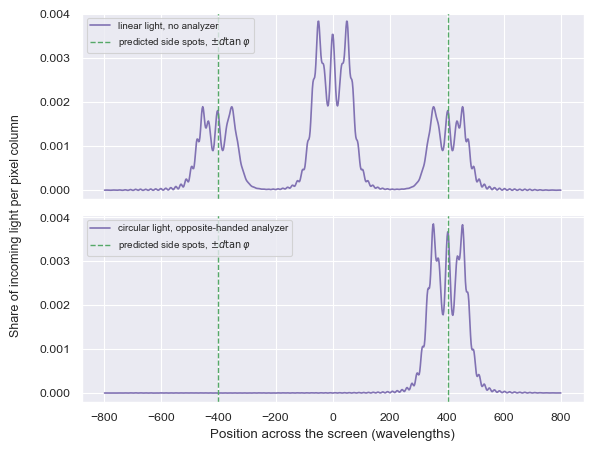

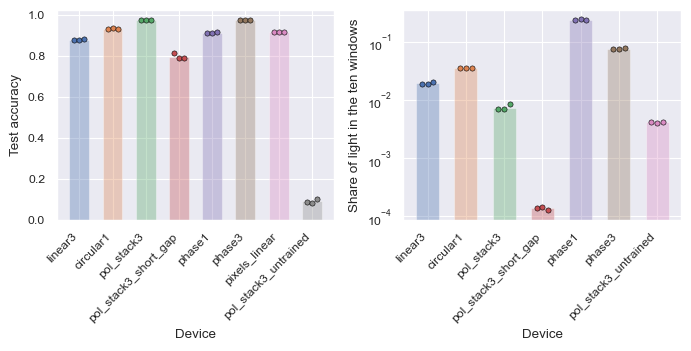

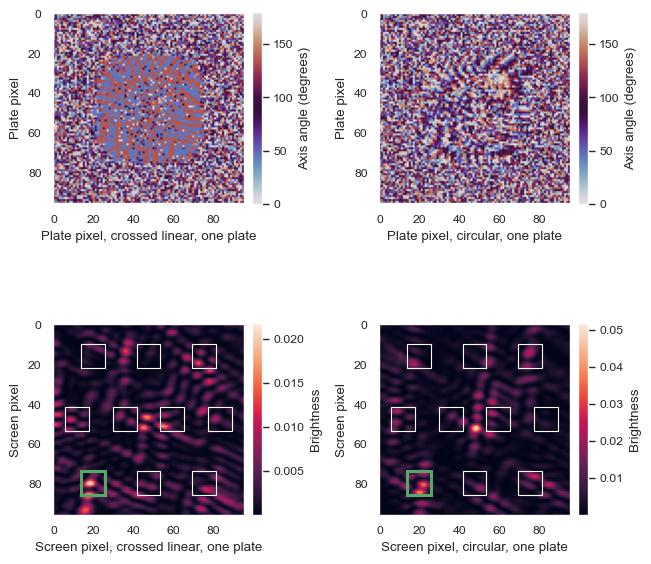

screen shown for test digit 0 (a 7); the window for 7 is the thick green outline
notebook live time: 59 s


In [10]:
# ---- figure 1: the grating orders
figure, axes = plt.subplots(2, 1, figsize=(6.0, 4.6), sharex=True)
shown = (screen_x.abs() <= 800).numpy()
for axis, light, label in ((axes[0], "linear", "linear light, no analyzer"), (axes[1], "circular", "circular light, opposite-handed analyzer")):
    axis.plot(screen_x.numpy()[shown], grating_columns[light].numpy()[shown], color=MODEL, label=label)
    for sign in (+1, -1):
        axis.axvline(sign * PREDICTED_SPOT, color=BOUND, linestyle="--", linewidth=1.0,
                     label="predicted side spots, $\\pm d \\tan\\varphi$" if sign == 1 else None)
    axis.legend(loc="upper left", fontsize=7)
axes[1].set_xlabel("Position across the screen (wavelengths)")
figure.supylabel("Share of incoming light per pixel column", fontsize=9)
figure.tight_layout()
figure.savefig(FIGURES / "optics_grating_orders.png", dpi=160, bbox_inches="tight")
plt.show()

# ---- figure 2: the devices
palette = sns.color_palette("deep")
figure, axes = plt.subplots(1, 2, figsize=(7.0, 3.6))
for axis, quantity, ylabel, log in ((axes[0], "accuracy", "Test accuracy", False), (axes[1], "delivered", "Share of light in the ten windows", True)):
    kinds = [kind for kind in DEVICE_ORDER if quantity in sweep["runs"][f"{kind}/0"]]
    for position, kind in enumerate(kinds):
        values = np.array(get_values(kind, quantity))
        axis.bar(position, values.mean(), width=0.6, color=palette[position % len(palette)], alpha=0.35)
        axis.scatter(position + np.linspace(-0.15, 0.15, len(values)), values, color=palette[position % len(palette)], s=14, zorder=3, edgecolor="black", linewidth=0.4)
    axis.set_xticks(range(len(kinds)))
    axis.set_xticklabels(kinds, rotation=45, ha="right")
    axis.set_ylabel(ylabel)
    if log:
        axis.set_yscale("log")
axes[0].set_xlabel("Device")
axes[1].set_xlabel("Device")
figure.tight_layout()
figure.savefig(FIGURES / "optics_devices.png", dpi=160, bbox_inches="tight")
plt.show()

# ---- figure 3: a trained angle map and the screen for one digit
from matplotlib.patches import Rectangle
figure, axes = plt.subplots(2, 2, figsize=(6.6, 6.4))
digit_index, digit_label = 0, int(test_labels[0])
half = optics.WINDOW_PIXELS // 2
for column, (kind, name) in enumerate((("linear3", "crossed linear, one plate"), ("circular1", "circular, one plate"))):
    angle_map = np.degrees(np.load(RESULTS / f"plate_{kind}.npy")[0] % math.pi)
    axes[0, column].grid(False)
    axes[1, column].grid(False)
    shown_map = axes[0, column].imshow(angle_map, cmap="twilight", vmin=0, vmax=180)
    axes[0, column].set_xlabel(f"Plate pixel, {name}")
    axes[0, column].set_ylabel("Plate pixel")
    figure.colorbar(shown_map, ax=axes[0, column], label="Axis angle (degrees)", fraction=0.046, pad=0.04)
    model = load_trained(kind)
    with torch.no_grad():
        screen, _ = model.get_screen(test_images[digit_index:digit_index + 1])
    pad = model.start
    crop = screen[0, pad:pad + optics.APERTURE_PIXELS, pad:pad + optics.APERTURE_PIXELS].numpy()
    image = axes[1, column].imshow(crop, cmap=sns.color_palette("rocket", as_cmap=True))
    for index, (row_centre, column_centre) in enumerate(optics.WINDOW_CENTRES):
        correct = index == digit_label
        axes[1, column].add_patch(Rectangle((column_centre - half - 0.5, row_centre - half - 0.5), 2 * half, 2 * half, fill=False,
                                            edgecolor="white" if not correct else "#55a868", linewidth=2.2 if correct else 0.8))
    axes[1, column].set_xlabel(f"Screen pixel, {name}")
    axes[1, column].set_ylabel("Screen pixel")
    figure.colorbar(image, ax=axes[1, column], label="Brightness", fraction=0.046, pad=0.04)
figure.tight_layout()
figure.savefig(FIGURES / "optics_plate.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"screen shown for test digit {digit_index} (a {digit_label}); the window for {digit_label} is the thick green outline")
print(f"notebook live time: {time.time() - NOTEBOOK_START:.0f} s")